# CNN ödevi
Bu notebook yönergedeki uygulamaları sırayla içerir. Hücreleri yukarıdan aşağıya çalıştırın. Teorik soruların cevapları rapordadır.

Bölümler: konvolüsyon ve 16 filtre, pooling, ReLU, Softmax, Fashion-MNIST, CNN, iki eğitim, grafikler ve karşılaştırma.

In [1]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import time
from pathlib import Path
from IPython.display import display, Markdown

# Aynı başlangıcı kullanmak için.
tf.keras.utils.set_random_seed(42)
tf.config.experimental.enable_op_determinism()
ciktilar = Path('ciktilar')
ciktilar.mkdir(exist_ok=True)

## 1 Konvolüsyon ve 16 filtrenin görselleştirilmesi
16 filtre, 16 özellik haritası üretir. Her filtre 3×3×1 boyutludur. Padding eklenmediği için 128−3+1=126 olur. weights biçimi (3,3,1,16), biases biçimi (16,) olur. he_normal, ReLU için uygun ağırlık başlangıcı sağlar. Görseldeki filtreler henüz eğitim görmemiştir.

Giriş: (1, 128, 128, 1)
Çıkış: (1, 126, 126, 16)
weights: (3, 3, 1, 16)
biases: (16,)
İlk filtre:
 [[-0.25283593  0.12861036 -0.75786656]
 [-0.21681367 -0.15182823 -0.702172  ]
 [ 0.23038778  0.76512676 -0.74278826]]


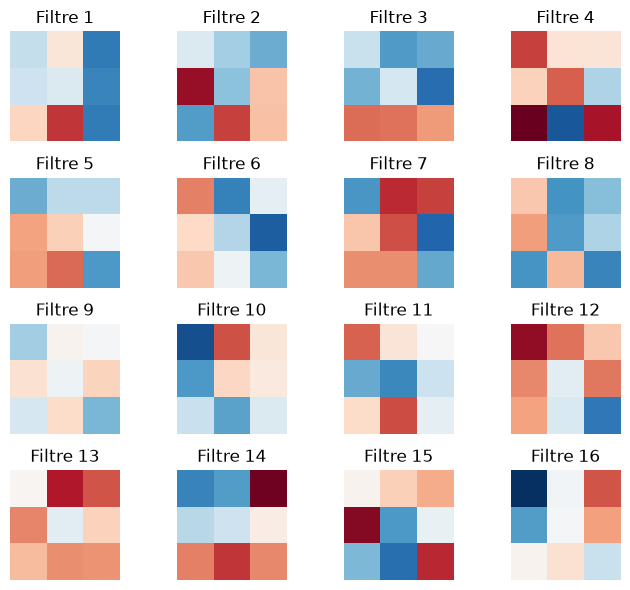

In [2]:
conv = tf.keras.layers.Conv2D(
    filters=16, kernel_size=(3,3),
    activation='relu', kernel_initializer='he_normal'
)
dummy_input = tf.random.normal((1,128,128,1))
output = conv(dummy_input)
weights, biases = conv.get_weights()
print('Giriş:', dummy_input.shape)
print('Çıkış:', output.shape)
print('weights:', weights.shape)
print('biases:', biases.shape)
print('İlk filtre:\n', weights[:,:,0,0])

fig, axes = plt.subplots(4,4,figsize=(7,6))
limit = np.max(np.abs(weights))
for i, ax in enumerate(axes.flat):
    ax.imshow(weights[:,:,0,i], cmap='RdBu_r', vmin=-limit, vmax=limit)
    ax.set_title(f'Filtre {i+1}')
    ax.axis('off')
plt.tight_layout()
plt.savefig(ciktilar/'filtreler.png',dpi=150)
plt.show()

## 2 Max Pooling
Her 2×2 bölgenin en büyük değeri alınır. Elle hesaplanan çıktı [[6,4],[7,9]] olur. Boyut 4×4'ten 2×2'ye düşer.

In [3]:
input_data = tf.constant([[[1.,3.,2.,4.], [5.,6.,1.,2.],
                           [7.,2.,8.,3.], [4.,1.,5.,9.]]])
input_data = tf.reshape(input_data,(1,4,4,1))
pool = tf.keras.layers.MaxPooling2D(pool_size=(2,2),strides=2)
output = pool(input_data)
elle = np.array([[6.,4.],[7.,9.]])
print('Giriş:\n', input_data.numpy()[0,:,:,0])
print('Pooling sonucu:\n', output.numpy()[0,:,:,0])
print('Boyut:', input_data.shape, '=>', output.shape)
print('Elle hesap ile aynı mı?', np.array_equal(elle,output.numpy()[0,:,:,0]))

Giriş:
 [[1. 3. 2. 4.]
 [5. 6. 1. 2.]
 [7. 2. 8. 3.]
 [4. 1. 5. 9.]]
Pooling sonucu:
 [[6. 4.]
 [7. 9.]]
Boyut: (1, 4, 4, 1) => (1, 2, 2, 1)
Elle hesap ile aynı mı? True


## 3 ReLU
ReLU negatifleri 0 yapar, pozitifleri korur. Ara katmanlara doğrusal olmayan dönüşüm ekler.

In [4]:
x = tf.constant([-5.,-2.,-1.,0.,2.,4.,6.])
y = tf.keras.layers.ReLU()(x)
print('Giriş:',x.numpy())
print('ReLU çıkışı:',y.numpy())

Giriş: [-5. -2. -1.  0.  2.  4.  6.]
ReLU çıkışı: [0. 0. 0. 0. 2. 4. 6.]


## 4 Softmax
Softmax sınıf puanlarını toplamı 1 olan olasılıklara dönüştürür. En yüksek olasılığın indeksi tahmin edilen sınıftır.

In [5]:
logits = tf.constant([[2.,1.,.1]])
probabilities = tf.keras.layers.Softmax()(logits)
print('Softmax:',probabilities.numpy())
print('Toplam:',tf.reduce_sum(probabilities).numpy())
print('Sınıf indeksi:',tf.argmax(probabilities[0]).numpy())

Softmax: [[0.6590012  0.24243298 0.09856589]]
Toplam: 1.0000001
Sınıf indeksi: 0


## 5 Fashion MNIST verisinin hazırlanması
Piksel değerlerini 255'e bölerek 0–1 aralığına getiriyoruz. Kanal boyutu ekliyoruz. 60.000 eğitim havuzundan 6.000 görüntü doğrulamaya ayrılacak. Testte 10.000 ayrı görüntü var.

In [6]:
(x_train,y_train),(x_test,y_test) = tf.keras.datasets.fashion_mnist.load_data()
x_train = x_train.astype('float32')/255.0
x_test = x_test.astype('float32')/255.0
x_train = x_train[...,np.newaxis]
x_test = x_test[...,np.newaxis]
print('Eğitim havuzu:',x_train.shape)
print('Test:',x_test.shape)

Eğitim havuzu: (60000, 28, 28, 1)
Test: (10000, 28, 28, 1)


## 6 Yönergedeki CNN modeli
İlk katmanın filtre sayısını seçebilmek için modeli küçük bir fonksiyonla kuruyoruz. Diğer katmanlar iki deneyde aynıdır. Flatten çıkışı 5×5×16=400'dür. Dense 64, 64 nöron demektir. Çıktıda 10 sınıf için 10 nöron var.

In [7]:
def model_olustur(ilk_filtre):
    return tf.keras.Sequential([
        tf.keras.layers.Input(shape=(28,28,1)),
        tf.keras.layers.Conv2D(ilk_filtre,(3,3),activation='relu'),
        tf.keras.layers.MaxPooling2D((2,2)),
        tf.keras.layers.Conv2D(16,(3,3),activation='relu'),
        tf.keras.layers.MaxPooling2D((2,2)),
        tf.keras.layers.Flatten(),
        tf.keras.layers.Dense(64,activation='relu'),
        tf.keras.layers.Dense(10,activation='softmax')
    ])
model8 = model_olustur(8)
model8.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_1 (Conv2D)               │ (None, 26, 26, 8)      │            80 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 13, 13, 8)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 11, 11, 16)     │         1,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 5, 5, 16)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 400)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │        25,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 27,562 (107.66 KB)

 Trainable params: 27,562 (107.66 KB)

 Non-trainable params: 0 (0.00 B)

## 7 Deney 1 ile eğitim 8 filtre
compile eğitim ayarlarını belirler, fit eğitir, evaluate test başarısını ölçer. Eğitim süresi yalnızca fit çağrısını kapsar. Epoch, eğitim verisinin bir tur işlenmesidir. Batch 64, örneklerin 64'lü gruplarla işlenmesidir.

In [8]:
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(42)
model8 = model_olustur(8)
model8.compile(optimizer='adam',loss='sparse_categorical_crossentropy',metrics=['accuracy'])

baslangic = time.perf_counter()
history8 = model8.fit(x_train,y_train,epochs=5,batch_size=64,validation_split=.1,verbose=2)
sure8 = time.perf_counter()-baslangic

test_loss8,test_accuracy8 = model8.evaluate(x_test,y_test,batch_size=64,verbose=0)
print('Test kaybı:',test_loss8)
print('Test doğruluğu:',test_accuracy8)
print('Eğitim süresi (s):',sure8)

Epoch 1/5


844/844 - 2s - 3ms/step - accuracy: 0.7700 - loss: 0.6284 - val_accuracy: 0.8205 - val_loss: 0.4833


Epoch 2/5


844/844 - 2s - 2ms/step - accuracy: 0.8463 - loss: 0.4224 - val_accuracy: 0.8452 - val_loss: 0.4244


Epoch 3/5


844/844 - 2s - 2ms/step - accuracy: 0.8641 - loss: 0.3750 - val_accuracy: 0.8620 - val_loss: 0.3845


Epoch 4/5


844/844 - 2s - 2ms/step - accuracy: 0.8753 - loss: 0.3451 - val_accuracy: 0.8683 - val_loss: 0.3573


Epoch 5/5


844/844 - 2s - 2ms/step - accuracy: 0.8824 - loss: 0.3230 - val_accuracy: 0.8762 - val_loss: 0.3372


Test kaybı: 0.3593571186065674
Test doğruluğu: 0.8708000183105469
Eğitim süresi (s): 9.252879332998418


## 8 Deney 2 ile eğitim 16 filtre
Yalnızca ilk konvolüsyon katmanının filtre sayısını 16 yapıyoruz. Veri, optimizer, epoch, batch ve doğrulama oranı aynı kalıyor.

In [9]:
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(42)
model16 = model_olustur(16)
model16.compile(optimizer='adam',loss='sparse_categorical_crossentropy',metrics=['accuracy'])

baslangic = time.perf_counter()
history16 = model16.fit(x_train,y_train,epochs=5,batch_size=64,validation_split=.1,verbose=2)
sure16 = time.perf_counter()-baslangic

test_loss16,test_accuracy16 = model16.evaluate(x_test,y_test,batch_size=64,verbose=0)
print('Test kaybı:',test_loss16)
print('Test doğruluğu:',test_accuracy16)
print('Eğitim süresi (s):',sure16)

Epoch 1/5


844/844 - 3s - 3ms/step - accuracy: 0.7810 - loss: 0.6117 - val_accuracy: 0.8328 - val_loss: 0.4698


Epoch 2/5


844/844 - 2s - 3ms/step - accuracy: 0.8548 - loss: 0.4030 - val_accuracy: 0.8585 - val_loss: 0.4055


Epoch 3/5


844/844 - 2s - 3ms/step - accuracy: 0.8715 - loss: 0.3559 - val_accuracy: 0.8688 - val_loss: 0.3718


Epoch 4/5


844/844 - 2s - 3ms/step - accuracy: 0.8799 - loss: 0.3287 - val_accuracy: 0.8738 - val_loss: 0.3533


Epoch 5/5


844/844 - 2s - 3ms/step - accuracy: 0.8873 - loss: 0.3077 - val_accuracy: 0.8763 - val_loss: 0.3428


Test kaybı: 0.3577776849269867
Test doğruluğu: 0.8741000294685364
Eğitim süresi (s): 11.806410666999


## 9 Eğitim ve doğrulama grafikleri
Accuracy doğru tahmin oranıdır. Loss modelin azaltmaya çalıştığı hatadır. Eğitim ve doğrulama çizgilerini birlikte inceliyoruz.

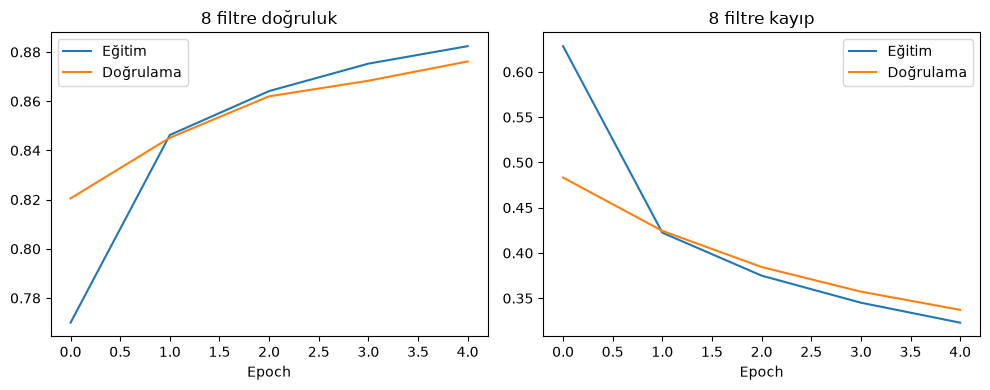

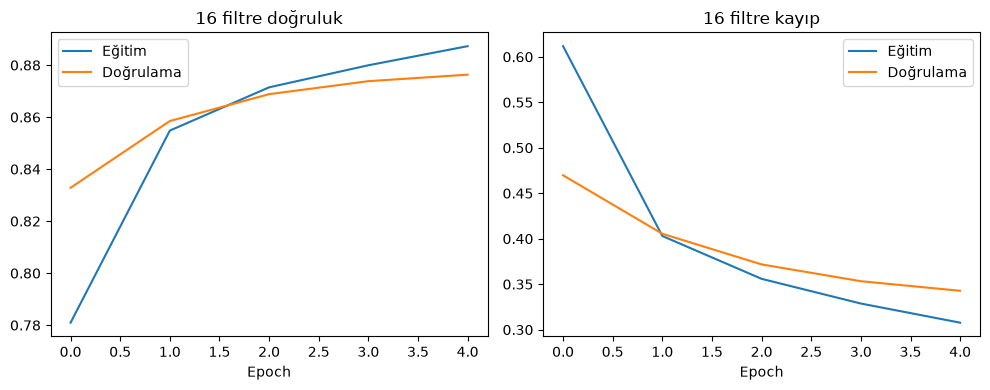

In [10]:
for history, ad in [(history8,'8 filtre'),(history16,'16 filtre')]:
    plt.figure(figsize=(10,4))
    plt.subplot(1,2,1)
    plt.plot(history.history['accuracy'],label='Eğitim')
    plt.plot(history.history['val_accuracy'],label='Doğrulama')
    plt.title(ad+' doğruluk'); plt.xlabel('Epoch'); plt.legend()
    plt.subplot(1,2,2)
    plt.plot(history.history['loss'],label='Eğitim')
    plt.plot(history.history['val_loss'],label='Doğrulama')
    plt.title(ad+' kayıp'); plt.xlabel('Epoch'); plt.legend()
    plt.tight_layout()
    plt.savefig(ciktilar/(ad.replace(' ','_')+'.png'),dpi=150)
    plt.show()

## 10 Deney karşılaştırması ve sonuç
Tabloyu gerçek eğitim çıktılarından oluşturuyoruz. Daha fazla filtre her zaman daha iyi sonuç vermez. Bu deneyde doğruluk ile süreyi birlikte değerlendiriyoruz. Farklı bilgisayarlarda süre ve doğruluklar değişebilir.

In [11]:
tablo = f"""| Ölçüt | 8 filtre | 16 filtre |
|---|---:|---:|
| Filtre sayısı | 8 | 16 |
| Eğitim doğruluğu | %{100*history8.history['accuracy'][-1]:.2f} | %{100*history16.history['accuracy'][-1]:.2f} |
| Test doğruluğu | %{100*test_accuracy8:.2f} | %{100*test_accuracy16:.2f} |
| Eğitim süresi (s) | {sure8:.2f} | {sure16:.2f} |
"""
display(Markdown(tablo))
print(f'Test doğruluğu farkı: {(test_accuracy16-test_accuracy8)*100:+.2f} yüzde puan')

| Ölçüt | 8 filtre | 16 filtre |
|---|---:|---:|
| Filtre sayısı | 8 | 16 |
| Eğitim doğruluğu | %88.24 | %88.73 |
| Test doğruluğu | %87.08 | %87.41 |
| Eğitim süresi (s) | 9.25 | 11.81 |


Test doğruluğu farkı: +0.33 yüzde puan


## Kaynaklar
Ödev yönergesi ÖDEV.docx, bölümler 2–9.

TensorFlow ve Keras resmi belgeleri: https://www.tensorflow.org/tutorials/keras/classification ve https://keras.io/api/